In [1]:
import pandas as pd
import numpy as np
import math
from scipy.stats import weibull_min
import sys
import os
from datetime import datetime, timedelta
import json


In [2]:
# Add EAMEET_v1 directory to path to import modules
current_dir = os.getcwd()

# If we're in the case study folder, go up one level
if os.path.basename(current_dir) == 'case study':
    project_root = os.path.dirname(current_dir)
else:
    # Search upward for EAMEET_v1 folder
    project_root = current_dir
    found = False
    
    while project_root != os.path.dirname(project_root):  # Stop at filesystem root
        eameet_v1_path = os.path.join(project_root, 'EAMEET_v1')
        if os.path.exists(eameet_v1_path) and os.path.isdir(eameet_v1_path):
            found = True
            break
        project_root = os.path.dirname(project_root)
    
    if not found:
        # Fallback: assume EAMEET_v1 is sibling to current directory
        project_root = os.path.dirname(current_dir)

# Verify EAMEET_v1 exists
eameet_v1_path = os.path.join(project_root, 'EAMEET_v1')
print(f"Looking for EAMEET_v1 at: {eameet_v1_path}")
print(f"EAMEET_v1 exists: {os.path.exists(eameet_v1_path)}")
print(f"Contents: {os.listdir(eameet_v1_path) if os.path.exists(eameet_v1_path) else 'N/A'}")

# Add EAMEET_v1 itself (not its parent) to sys.path: simulations.py/utils.py use
# absolute imports (e.g. "from utils import ..."), so the package directory
# itself must be on sys.path rather than imported as a dotted sub-package.
if eameet_v1_path not in sys.path:
    sys.path.insert(0, eameet_v1_path)
    print(f"Added to path: {eameet_v1_path}")

import simulations as sim
import utils as utils

Looking for EAMEET_v1 at: /Users/mo/Desktop/Event-based-Annualized-Emissions-Estimation-Toolkit-main/EAMEET_v1
EAMEET_v1 exists: True
Contents: ['validate_occupancy_recovery.py', 'annualize.py', 'EAMEET_dash_app.py', 'weather_permian.nc', '.DS_Store', 'version.py', 'worked_examples_merging.py', 'requirements.txt', 'validate_simulation.py', '.pytest_cache', 'CHANGELOG.md', 'test_basic_functionality.py', 'occupancy.py', 'test_validate_occupancy_recovery.py', 'validation_outputs', 'sample_emission_events.csv', 'test_below_mdl_coverage.py', 'sample_leak_rate.csv', 'RUNBOOK.md', 'simulations.py', 'validate_annual_truth.py', '__pycache__', 'README.md', 'test_conditional_duration.py', 'utils.py', 'test_event_converter.py', 'VALIDATION_GUIDE.md', 'components.py', 'emission_event_converter.py', 'test_leak_rate_units.py', 'assets', 'requirements-lock.txt', 'test_event_integration.py', 'test_extrapolation_renewal.py', 'QUICK_START.md', 'test_occupancy.py']
Added to path: /Users/mo/Desktop/Event-b

#### Load plumes and sources downloaded from Carbon Mapper

In [3]:
# Load sources 
features = [] 
with open("CM_sources.json", 'r') as f: 
    data = json.load(f)
    feats = data["features"]
    for feat in feats: 
        if feat not in features: 
            features.append(feat) 
cm_sources = pd.DataFrame(features)

sources = []
for _,row in cm_sources.iterrows():
    plume_ids = row.properties.get("plume_ids") 
    plume_2024 = False  
    for plume_id in plume_ids: 
        if "2024" in plume_id:
            plume_2024 = True
    # Reviewer comment 6: keep oil-and-gas sources only (IPCC 1B2); the download also lists one
    # coal-mining (1B1a), one livestock (4B) and two unclassified sources, which are excluded.
    if plume_2024 and row.properties.get("sector") == "1B2": 
        sources.append({
            "source_name": row.id, 
            "source_lon": row.geometry.get("coordinates")[0],
            "source_lat": row.geometry.get("coordinates")[1],
            "plume_count":row.properties.get("plume_count"),
            "scene_count":len(row.properties.get("observation_scenes_names")),
            "scene_names": row.properties.get("observation_scenes_names"),
            "plume_ids": row.properties.get("plume_ids"),
            "persistence": row.properties.get("persistence"),
            "detection_date_count": row.properties.get("detection_date_count"),
            "observation_date_count": row.properties.get("observation_date_count"),
            "published_at_max": row.properties.get("published_at_max"),
            "published_at_min": row.properties.get("published_at_min"),
            "timestamp_max": row.properties.get("timestamp_max"),
            "timestamp_min": row.properties.get("timestamp_min"),
            "source_rate": row.properties.get("emission_auto"),
            "source_rate_unc": row.properties.get("emission_uncertainty_auto"),
        })
        
source_df = pd.DataFrame(sources)

In [4]:
# load plumes
plume_df = pd.read_csv(r"CM_plumes.csv")

#### Join plume and source to create emission observations

In [5]:
# Emission observations and emission events are built by cs1_build_events.py (reviewer comment 6):
#   * sector filter: oil and gas (IPCC 1B2) sources only;
#   * all three Carbon Mapper platforms of 2024 (GAO airborne, EMIT, Tanager-1). The earlier version of this
#     cell tested `"2024" in plume.split("t")[0]`, which is empty for Tanager identifiers ("tan2024...") and
#     therefore silently dropped every Tanager-1 plume;
#   * plumes without an automated quantification are dropped and counted;
#   * null detections = observation scenes of the source without a plume.
# The script writes CM_emissions_observation.csv and converts the observations into events with the toolkit
# (EAMEET_v1/emission_event_converter.py), writing CM_emission_events.csv and cs1_outputs/cs1_dataset_composition.md.
%run cs1_build_events.py


| Item | Value |
|---|---|
| Sources in download | 662 |
| Sources dropped by sector filter (not 1B2) | 4 (NA, NA, 4B, 1B1a) |
| 1B2 sources with >= 1 quantified 2024 detection (event cohort) | 629 |
| Quantified positive detections 2024 | 1321 |
| &nbsp;&nbsp; GAO (airborne) | 1107 |
| &nbsp;&nbsp; Tanager-1 (satellite) | 171 |
| &nbsp;&nbsp; EMIT (ISS, satellite) | 43 |
| Valid null detections (scenes without a plume, 2023-2024) | 2471 |
| &nbsp;&nbsp; null detections in 2024 | 2464 |
| Emission events | 806 |
| Events with > 1 detection | 233 |
| Observation dates per source (median) | 4 |
| plume without quantification (dropped) | 125 |
| plume id not in plume file | 1 |

GAO detection dates: 2024-04-30 -> 2024-05-17
wrote CM_emissions_observation.csv, CM_emission_events.csv, cs1_outputs/cs1_dataset_composition.md


In [6]:
EO = pd.read_csv("CM_emissions_observation.csv", parse_dates=["observation_time"])


In [7]:
print(len(EO))
EO.head()

3792


,id,rate,rate_uncertainty,source,lon,lat,persistence,observation_time,measurement_technology,platform,sector,detection
0,CH4_1B2_250m_-101.26737_31.15282?datetime=2024...,0.000000,0.000000,CH4_1B2_250m_-101.26737_31.15282?datetime=2024...,-101.267372,31.152821,0.25,2024-02-04 16:50:03,emi,"EMIT (ISS, satellite)",1B2,False
1,CH4_1B2_250m_-101.26737_31.15282?datetime=2024...,0.000000,0.000000,CH4_1B2_250m_-101.26737_31.15282?datetime=2024...,-101.267372,31.152821,0.25,2024-02-12 21:48:55,emi,"EMIT (ISS, satellite)",1B2,False
2,emi20240731t181643p12010-A,5864.327475,854.840936,CH4_1B2_250m_-101.26737_31.15282?datetime=2024...,-101.267372,31.152821,0.25,2024-07-31 18:16:43,emi,"EMIT (ISS, satellite)",1B2,True
3,CH4_1B2_250m_-101.26737_31.15282?datetime=2024...,0.000000,0.000000,CH4_1B2_250m_-101.26737_31.15282?datetime=2024...,-101.267372,31.152821,0.25,2024-09-27 19:17:27,emi,"EMIT (ISS, satellite)",1B2,False
4,emi20240127t195915p13009-C,3532.281053,395.390444,CH4_1B2_250m_-101.32793_32.36330?datetime=2024...,-101.327929,32.363300,0.25,2024-01-27 19:59:15,emi,"EMIT (ISS, satellite)",1B2,True


In [8]:
# (written by cs1_build_events.py)
print("positive detections:", int((EO.rate > 0).sum()), "| null detections:", int((EO.rate == 0).sum()), "| sources:", EO.source.nunique())
print(EO[EO.rate > 0].platform.value_counts())


positive detections: 1321 | null detections: 2471 | sources: 629
platform
GAO (airborne)           1107
Tanager-1 (satellite)     171
EMIT (ISS, satellite)      43
Name: count, dtype: int64


#### Convert plumes to emission events

In [9]:
event_df = pd.read_csv(r"CM_emission_events.csv")
event_df["startTime"] = pd.to_datetime(event_df["startTime"])
event_df["endTime"] = pd.to_datetime(event_df["endTime"])

In [10]:
event_df.head(2)

,id,rate,duration,quantity,sourceLocation,startTime,endTime,merged_from,event_type,first_detection,last_detection,n_observations,uncertainties
0,15d0e89f-1e49-43ab-8d70-1e5242b2020a,5864.327475,5469.475556,3.207480e+07,CH4_1B2_250m_-101.26737_31.15282?datetime=2024...,2024-02-12 21:48:55,2024-09-27 19:17:27,emi20240731t181643p12010-A,PRE,2024-07-31T18:16:43,2024-07-31T18:16:43,1,854.840936
1,d1f12d6d-1da2-4093-9781-0e3db205b8be,3532.281053,4988.979444,1.762248e+07,CH4_1B2_250m_-101.32793_32.36330?datetime=2024...,2023-07-31 19:59:15,2024-02-24 16:58:01,emi20240127t195915p13009-C,PRE,2024-01-27T19:59:15,2024-01-27T19:59:15,1,395.390444


In [11]:
# expected duration distribution 
durations = list(event_df.duration) 
durations_clean = [x for x in durations if math.isfinite(x) and x>0]
dur_dist = list(utils.fitting_distribution(durations_clean,"weibull"))
# expected rate distribution 
clean_plume_df = event_df.dropna(subset = ["rate"])
rates_clean = list(clean_plume_df.rate)
rate_dist = list(utils.fitting_distribution(rates_clean,"weibull"))

In [12]:
uncertainty_percents = [] 
event_uncertainties = event_df.uncertainties
event_rates = event_df.rate

for ele in zip(event_rates,event_uncertainties): 
    uncertainty_percents.append(ele[1]/ele[0])

In [13]:
n_samples = 10000
rate_samples = [] 
for n in range(n_samples):
    sr = weibull_min.rvs(*rate_dist, size=1)[0]
    unc = np.random.choice(uncertainty_percents)
    if unc < 1: 
        sr = sr + sr * np.random.uniform(-unc, unc)
    else:
        sr = sr 
    rate_samples.append(sr)
duration_samples = list(weibull_min.rvs(*dur_dist, size=n_samples))

In [14]:
len(event_df.sourceLocation.unique())

629

In [15]:
len(event_df)

806

### Simulation 

In [16]:
# ---- Joint Monte Carlo ensemble (reviewer comment 1, second round) ----
# The ensemble engine lives in cs1_joint_ensemble.py (same folder) so that the notebook, the SI tables and the
# dependence tests use one implementation. Per outer iteration it samples, BEFORE any aggregation:
#   * the quantification error of every plume (mean-preserving lognormal from the Carbon Mapper reported
#     uncertainty), optionally with a component shared by all plumes of one platform on one day (wind-field /
#     retrieval error, rho_day) and a platform-wide calibration bias (sigma_platform) -- see the dependence tests;
#   * the event rates (mean of the sampled plume rates) and, optionally, detection-conditioned event durations;
#   * the Weibull rate and duration distributions of the UE simulation, refit to a bootstrap resample of THIS
#     iteration's sampled events (the "PREs parameterize UEs" dependence);
#   * each source's event occupancy from its detection-record posterior (EAMEET_v1/occupancy.py, Section S9):
#     Carbon Mapper persistence (k detection dates / m observation dates) is a biased occupancy estimate because an
#     emitting source is detected only with probability POD < 1, m is small, and only sources with k >= 1 are listed;
#     k ~ Binomial(m, phi*POD) truncated at k >= 1 with an empirical-Bayes Beta population prior;
#   * the unresolved emissions of each source over its unobserved hours (alternating renewal process).
# PRE + UE are summed within the iteration and across all sources. The reported central estimate and 95% CI are
# the median and the 2.5th / 97.5th percentiles of this ensemble of basin totals -- never a sum of component
# medians or bounds, and never a root-sum-square of a bound and an uncertainty magnitude.
import multiprocessing as _mp
try:
    _mp.set_start_method("fork", force=True)
except RuntimeError:
    pass
from cs1_joint_ensemble import load_case, build_occupancy, run_ensemble, run_dependence_tests, summarize

POD_CM = 0.9
N_OUTER = 10_000

pooled_rates = np.asarray(rates_clean, dtype=float)
pooled_durations = np.asarray(durations_clean, dtype=float)
n_pool = len(pooled_rates)

CASE = load_case()                       # events, plumes (with platform and day), sources
OCC = build_occupancy(CASE, POD_CM)      # empirical-Bayes prior and per-source posterior CDFs

import time as _time
_t0 = _time.time()
OCC_PRIOR, source_info, pre_draws, ue_draws = run_ensemble(POD_CM, N_OUTER, seed=2024, case=CASE, occ=OCC)
ENSEMBLE_SECONDS = _time.time() - _t0
print(f"Joint ensemble: {N_OUTER} iterations x {len(source_info)} sources in {ENSEMBLE_SECONDS/60:.1f} min "
      f"({os.cpu_count()} cores)")
print(f"Occupancy prior (empirical Bayes, POD_CM={POD_CM}): Beta(a={OCC_PRIOR[0]:.3f}, b={OCC_PRIOR[1]:.3f})")

total_draws = pre_draws + ue_draws
basin_total_draws = total_draws.sum(axis=1)


def _summ(draws):
    med = np.median(draws, axis=0)
    lo = med - np.percentile(draws, 2.5, axis=0)
    hi = np.percentile(draws, 97.5, axis=0) - med
    return med, lo, hi


pre_med, pre_lo, pre_hi = _summ(pre_draws)
ue_med, ue_lo, ue_hi = _summ(ue_draws)
tot_med, tot_lo, tot_hi = _summ(total_draws)

source_emissions = []
for s, info in enumerate(source_info):
    occ = info["occupancy"] or {}
    source_emissions.append({
        "source": info["source"],
        "detection_dates": occ.get("k"), "observation_dates": occ.get("m"),
        "persistence": occ.get("persistence"),
        "occupancy_mean": occ.get("mean"), "occupancy_q2.5": occ.get("q2.5"), "occupancy_q97.5": occ.get("q97.5"),
        "pre_emissions": pre_med[s], "pre_emissions_lower": pre_lo[s], "pre_emissions_upper": pre_hi[s],
        "ue_emissions": ue_med[s], "ue_emissions_lower": ue_lo[s], "ue_emissions_upper": ue_hi[s],
        "total_emissions": tot_med[s], "total_emissions_lower": tot_lo[s], "total_emissions_upper": tot_hi[s],
    })

np.save("cs1_basin_total_ensemble.npy", basin_total_draws)
print(f"Basin PRE total (median): {np.median(pre_draws.sum(axis=1))/1e9:.3f} Tg;  "
      f"basin UE total (median): {np.median(ue_draws.sum(axis=1))/1e9:.3f} Tg")
print(f"Basin total (joint ensemble, N={N_OUTER}): median={np.median(basin_total_draws)/1e9:.3f} Tg, "
      f"95% CI [{np.percentile(basin_total_draws,2.5)/1e9:.3f}, {np.percentile(basin_total_draws,97.5)/1e9:.3f}] Tg")


Joint ensemble: 10000 iterations x 629 sources in 0.6 min (12 cores)
Occupancy prior (empirical Bayes, POD_CM=0.9): Beta(a=0.050, b=1.298)


Basin PRE total (median): 1.263 Tg;  basin UE total (median): 0.817 Tg
Basin total (joint ensemble, N=10000): median=2.082 Tg, 95% CI [1.921, 2.285] Tg


In [17]:
sdf = pd.DataFrame( source_emissions)
sdf.to_csv("total_emissions.csv")

In [18]:
naive_sum = sum(se["total_emissions"] for se in source_emissions)
print(f"Basin total (sum of per-source point medians): {naive_sum/1e9:.3f} Tg")
print(f"Basin total (joint ensemble -- central estimate and 95% CI): "
      f"median={np.median(basin_total_draws)/1e9:.3f} Tg, "
      f"95% CI [{np.percentile(basin_total_draws,2.5)/1e9:.3f}, {np.percentile(basin_total_draws,97.5)/1e9:.3f}] Tg")

Basin total (sum of per-source point medians): 1.577 Tg
Basin total (joint ensemble -- central estimate and 95% CI): median=2.082 Tg, 95% CI [1.921, 2.285] Tg


Sources: 629;  mean raw persistence 0.567;  mean posterior occupancy 0.372
            n  persistence  occupancy
attempts                             
1         137        1.000      0.447
2-3       163        0.570      0.391
4-6       301        0.393      0.336
7+         28        0.306      0.286


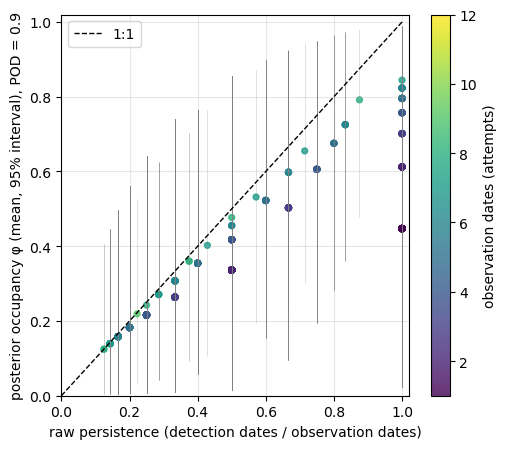

In [19]:
# ---- Occupancy estimates vs raw persistence (SI table + figure) ----
import matplotlib.pyplot as plt
os.makedirs("cs1_outputs", exist_ok=True)
occ_df = pd.DataFrame([r for r in source_emissions if r["persistence"] is not None])
occ_df[["source", "detection_dates", "observation_dates", "persistence",
        "occupancy_mean", "occupancy_q2.5", "occupancy_q97.5", "ue_emissions"]].to_csv(
    "cs1_outputs/cs1_source_occupancy.csv", index=False)

print(f"Sources: {len(occ_df)};  mean raw persistence {occ_df.persistence.mean():.3f};  "
      f"mean posterior occupancy {occ_df.occupancy_mean.mean():.3f}")
grp = occ_df.assign(attempts=pd.cut(occ_df.observation_dates, [0, 1, 3, 6, 100], labels=["1", "2-3", "4-6", "7+"]))
summary = grp.groupby("attempts", observed=True).agg(n=("source", "size"), persistence=("persistence", "mean"),
                                                    occupancy=("occupancy_mean", "mean")).round(3)
print(summary.to_string())
summary.to_csv("cs1_outputs/cs1_occupancy_by_attempts.csv")

fig, ax = plt.subplots(figsize=(5.2, 4.6))
sc = ax.scatter(occ_df.persistence, occ_df.occupancy_mean, c=occ_df.observation_dates, cmap="viridis",
                s=18, alpha=0.8, vmin=1, vmax=12)
ax.errorbar(occ_df.persistence, occ_df.occupancy_mean,
            yerr=[occ_df.occupancy_mean - occ_df["occupancy_q2.5"], occ_df["occupancy_q97.5"] - occ_df.occupancy_mean],
            fmt="none", ecolor="grey", elinewidth=0.4, alpha=0.4)
ax.plot([0, 1], [0, 1], "k--", lw=1, label="1:1")
ax.set_xlabel("raw persistence (detection dates / observation dates)")
ax.set_ylabel(f"posterior occupancy φ (mean, 95% interval), POD = {POD_CM}")
ax.set_xlim(0, 1.02); ax.set_ylim(0, 1.02); ax.grid(alpha=0.3); ax.legend(loc="upper left")
fig.colorbar(sc, ax=ax, label="observation dates (attempts)")
fig.tight_layout(); fig.savefig("cs1_outputs/cs1_occupancy_vs_persistence.png", dpi=200); plt.show()


In [20]:
# ---- Sensitivity of the basin total to the assumed Carbon Mapper POD ----
N_OUTER_SENS = 2000
sens_rows = []
for pod_cm in [0.6, 0.75, 0.9, 1.0]:
    prior_s, info_s, pre_s, ue_s = run_ensemble(pod_cm, N_OUTER_SENS, seed=7, case=CASE)
    tot_s = (pre_s + ue_s).sum(axis=1)
    occ_means = [i["occupancy"]["mean"] for i in info_s if i["occupancy"]]
    sens_rows.append({"POD_CM": pod_cm, "prior_a": prior_s[0], "prior_b": prior_s[1],
                      "mean_occupancy": float(np.mean(occ_means)),
                      "UE_Tg_median": np.median(ue_s.sum(axis=1)) / 1e9,
                      "total_Tg_median": np.median(tot_s) / 1e9,
                      "total_Tg_q2.5": np.percentile(tot_s, 2.5) / 1e9,
                      "total_Tg_q97.5": np.percentile(tot_s, 97.5) / 1e9})
sens_df = pd.DataFrame(sens_rows).round(4)
sens_df.to_csv("cs1_outputs/cs1_pod_sensitivity.csv", index=False)
print(sens_df.to_string(index=False))


 POD_CM  prior_a  prior_b  mean_occupancy  UE_Tg_median  total_Tg_median  total_Tg_q2.5  total_Tg_q97.5
   0.60     0.05   0.7314          0.5204        1.1607           2.4239         2.2142          2.6810
   0.75     0.05   1.0147          0.4347        0.9612           2.2249         2.0491          2.4417
   0.90     0.05   1.2983          0.3724        0.8155           2.0791         1.9240          2.2883
   1.00     0.05   1.4960          0.3389        0.7396           2.0037         1.8564          2.1935


In [21]:
# ---- Sensitivity of the basin total to joint (paired) rate-duration sampling (reviewer comment 4) ----
# The observed Carbon Mapper events show a weak positive rank correlation between rate and duration
# (Spearman rho = 0.33, n = 806). Independent sampling of the Weibull marginals ignores it; the paired
# scheme keeps it through the empirical copula of the bootstrap-resampled pairs.
from scipy.stats import spearmanr
rho, pval = spearmanr(pooled_rates, pooled_durations)
print(f"Observed events: Spearman rho = {rho:.3f} (p = {pval:.1e}, n = {n_pool})")
samp_rows = []
for sampling in ["independent", "paired"]:
    prior_j, info_j, pre_j, ue_j = run_ensemble(POD_CM, N_OUTER_SENS, seed=7, sampling=sampling, case=CASE, occ=OCC)
    tot_j = (pre_j + ue_j).sum(axis=1)
    samp_rows.append({"sampling": sampling, "POD_CM": POD_CM, "N_outer": N_OUTER_SENS,
                      "UE_Tg_median": np.median(ue_j.sum(axis=1)) / 1e9,
                      "total_Tg_median": np.median(tot_j) / 1e9,
                      "total_Tg_q2.5": np.percentile(tot_j, 2.5) / 1e9,
                      "total_Tg_q97.5": np.percentile(tot_j, 97.5) / 1e9})
samp_df = pd.DataFrame(samp_rows).round(4)
samp_df["change_vs_independent_pct"] = ((samp_df.total_Tg_median / samp_df.total_Tg_median.iloc[0] - 1) * 100).round(1)
samp_df.to_csv("cs1_outputs/cs1_sampling_sensitivity.csv", index=False)
print(samp_df.to_string(index=False))


Observed events: Spearman rho = 0.327 (p = 1.4e-21, n = 806)


   sampling  POD_CM  N_outer  UE_Tg_median  total_Tg_median  total_Tg_q2.5  total_Tg_q97.5  change_vs_independent_pct
independent     0.9     2000        0.8155           2.0791          1.924          2.2883                        0.0
     paired     0.9     2000        1.5736           2.8368          2.382          3.4230                       36.4


In [22]:
# ---- Preferential sampling of large emitters (reviewer comment 6): how much of the basin total rests on
# transferring the pooled (detection-biased) rate distribution to the unobserved time of every source?
# Bounds: (a) baseline pooled rates; (b) each source's UE rates drawn only from its OWN observed rates;
# (c) no extrapolation at all (PRE events only, UE = 0). The PRE term itself is unaffected by the choice.
prior_b, info_b, pre_b, ue_b = run_ensemble(POD_CM, N_OUTER_SENS, seed=7, rate_source="pooled", case=CASE, occ=OCC)
prior_o, info_o, pre_o, ue_o = run_ensemble(POD_CM, N_OUTER_SENS, seed=7, rate_source="own", case=CASE, occ=OCC)
pref_rows = []
for label, pre_x, ue_x in [("pooled basin-wide rate distribution (baseline)", pre_b, ue_b),
                           ("source-specific rates (own observed rates only)", pre_o, ue_o),
                           ("no extrapolation (PRE events only)", pre_b, np.zeros_like(ue_b))]:
    tot_x = (pre_x + ue_x).sum(axis=1)
    pref_rows.append({"UE rate source": label, "N_outer": N_OUTER_SENS,
                      "PRE_Tg_median": np.median(pre_x.sum(axis=1)) / 1e9,
                      "UE_Tg_median": np.median(ue_x.sum(axis=1)) / 1e9,
                      "total_Tg_median": np.median(tot_x) / 1e9,
                      "total_Tg_q2.5": np.percentile(tot_x, 2.5) / 1e9,
                      "total_Tg_q97.5": np.percentile(tot_x, 97.5) / 1e9})
pref_df = pd.DataFrame(pref_rows).round(4)
pref_df["change_vs_baseline_pct"] = ((pref_df.total_Tg_median / pref_df.total_Tg_median.iloc[0] - 1) * 100).round(1)
pref_df.to_csv("cs1_outputs/cs1_preferential_sampling.csv", index=False)
print(pref_df.to_string(index=False))


                                 UE rate source  N_outer  PRE_Tg_median  UE_Tg_median  total_Tg_median  total_Tg_q2.5  total_Tg_q97.5  change_vs_baseline_pct
 pooled basin-wide rate distribution (baseline)     2000         1.2633        0.8155           2.0791         1.9240          2.2883                     0.0
source-specific rates (own observed rates only)     2000         1.2635        0.7169           1.9800         1.8589          2.1186                    -4.8
             no extrapolation (PRE events only)     2000         1.2633        0.0000           1.2633         1.2236          1.3060                   -39.2


In [23]:
# ---- Dependence tests of the joint ensemble (reviewer comment 1): shared quantification errors, the PRE -> UE
# link and sampled durations. Each variant re-runs the complete ensemble (N_OUTER_SENS iterations, POD = 0.9):
#   A  baseline (independent plume errors from the reported uncertainties, bracket durations, bootstrap refit on the
#      sampled rates);  B  no bootstrap refit (contribution of fitted-parameter uncertainty);  C  UE distributions
#   refit to the reported rather than the sampled rates (PRE -> UE link cut);  D/E  half / all of each plume's error
#   variance shared by all plumes of one platform on one day (wind-field / retrieval error);  F  platform-wide
#   calibration bias (log-SD 0.2 per platform);  G  F with the PRE -> UE link cut;  H  fully shared (F + E);
#   I  detection-conditioned PRE durations sampled per event and iteration (Section S3) instead of the deterministic
#   null-detection bracket;  J  I with fully shared errors.
# Shared errors leave the median almost unchanged (the errors are mean-preserving) but widen the interval; the
# relative width is reported so the widening can be compared with the baseline. Output: cs1_outputs/cs1_dependence_tests.{csv,md}
dep_df = run_dependence_tests(N_OUTER_SENS, seed=7, pod_cm=POD_CM, case=CASE, occ=OCC)
dep_df[["variant", "PRE_Tg_median", "UE_Tg_median", "total_Tg_median", "total_Tg_q2.5", "total_Tg_q97.5",
        "rel_width_95", "change_median_pct", "width_ratio_vs_baseline"]].round(3)


A: total 2.079 [1.924, 2.288] Tg, PRE 1.263, UE 0.816, rel. width 0.175 (7.9 s)  -- Baseline: independent plume errors, bracket durations, bootstrap refit on the sampled rates


B: total 2.090 [1.967, 2.233] Tg, PRE 1.264, UE 0.827, rel. width 0.127 (5.0 s)  -- No parameter uncertainty: Weibull fitted once to the observed sample (no bootstrap refit)


C: total 2.086 [1.935, 2.288] Tg, PRE 1.263, UE 0.822, rel. width 0.169 (8.7 s)  -- UE distributions refit to the reported (unperturbed) rates, i.e. PRE rate errors not passed to the UEs


D: total 2.079 [1.880, 2.309] Tg, PRE 1.262, UE 0.819, rel. width 0.206 (7.9 s)  -- Half of each plume's error variance shared within (platform, day): rho = 0.5


E: total 2.078 [1.856, 2.349] Tg, PRE 1.260, UE 0.817, rel. width 0.238 (7.4 s)  -- All of each plume's error shared within (platform, day): rho = 1


...

G: total 2.085 [1.761, 2.504] Tg, PRE 1.252, UE 0.822, rel. width 0.356 (8.2 s)  -- Platform-wide bias (0.2) with the UE distributions refit to the reported rates (link PRE -> UE cut)


H: total 2.057 [1.587, 2.652] Tg, PRE 1.248, UE 0.803, rel. width 0.518 (7.7 s)  -- Fully shared errors: platform-wide bias (0.2) and rho = 1


I: total 1.523 [1.342, 1.747] Tg, PRE 0.606, UE 0.919, rel. width 0.266 (7.7 s)  -- Detection-conditioned PRE durations sampled per event (Section S3), independent plume errors


J: total 1.505 [1.158, 1.984] Tg, PRE 0.596, UE 0.909, rel. width 0.549 (7.6 s)  -- Detection-conditioned durations with fully shared errors (platform bias 0.2, rho = 1)


,variant,PRE_Tg_median,UE_Tg_median,total_Tg_median,total_Tg_q2.5,total_Tg_q97.5,rel_width_95,change_median_pct,width_ratio_vs_baseline
0,A,1.263,0.816,2.079,1.924,2.288,0.175,0.000,1.000
1,B,1.264,0.827,2.090,1.967,2.233,0.127,0.536,0.726
2,C,1.263,0.822,2.086,1.935,2.288,0.169,0.323,0.966
3,D,1.262,0.819,2.079,1.880,2.309,0.206,0.008,1.176
4,E,1.260,0.817,2.078,1.856,2.349,0.238,-0.050,1.356
5,F,1.252,0.810,2.074,1.622,2.654,0.497,-0.251,2.839
6,G,1.252,0.822,2.085,1.761,2.504,0.356,0.283,2.034
7,H,1.248,0.803,2.057,1.587,2.652,0.518,-1.074,2.956
8,I,0.606,0.919,1.523,1.342,1.747,0.266,-26.729,1.517
9,J,0.596,0.909,1.505,1.158,1.984,0.549,-27.620,3.134


In [24]:
# ---- Monte Carlo convergence and computational cost of the joint ensemble (reviewer comment 7)
import time, platform, os
conv_rows = []
for n in [500, 1000, 2000, 5000]:
    t0 = time.time()
    _, _, pre_c, ue_c = run_ensemble(POD_CM, n, seed=11, case=CASE, occ=OCC)
    tot_c = (pre_c + ue_c).sum(axis=1)
    conv_rows.append({"N_outer": n, "seconds": round(time.time() - t0, 1),
                      "total_Tg_median": np.median(tot_c) / 1e9,
                      "total_Tg_q2.5": np.percentile(tot_c, 2.5) / 1e9,
                      "total_Tg_q97.5": np.percentile(tot_c, 97.5) / 1e9,
                      "MC_SE_of_median_Tg": 1.2533 * np.std(tot_c) / np.sqrt(n) / 1e9})
conv_rows.append({"N_outer": N_OUTER, "seconds": round(ENSEMBLE_SECONDS, 1),
                  "total_Tg_median": np.median(basin_total_draws) / 1e9,
                  "total_Tg_q2.5": np.percentile(basin_total_draws, 2.5) / 1e9,
                  "total_Tg_q97.5": np.percentile(basin_total_draws, 97.5) / 1e9,
                  "MC_SE_of_median_Tg": 1.2533 * np.std(basin_total_draws) / np.sqrt(N_OUTER) / 1e9})
conv_df = pd.DataFrame(conv_rows).round(4)
conv_df["machine"] = f"{platform.machine()}, {os.cpu_count()} cores, python {platform.python_version()}"
conv_df.to_csv("cs1_outputs/cs1_mc_convergence.csv", index=False)
print(conv_df.to_string(index=False))


 N_outer  seconds  total_Tg_median  total_Tg_q2.5  total_Tg_q97.5  MC_SE_of_median_Tg                        machine
     500      2.0           2.0749         1.9191          2.2868              0.0053 arm64, 12 cores, python 3.13.9
    1000      3.8           2.0778         1.9141          2.2881              0.0037 arm64, 12 cores, python 3.13.9
    2000      7.9           2.0806         1.9182          2.2801              0.0026 arm64, 12 cores, python 3.13.9
    5000     18.8           2.0820         1.9185          2.2841              0.0017 arm64, 12 cores, python 3.13.9
   10000     37.2           2.0816         1.9208          2.2855              0.0012 arm64, 12 cores, python 3.13.9
